# Análisis de una imagen: ejercicios resueltos

Se resuelven las actividades presentes en el notebook con la fotografía `beagle.jpg`: estructura RGB, estadísticas, visualización de canales, comparación de medias, organización en un DataFrame e histograma. Las celdas se ejecutan en orden desde un kernel limpio.

## 1. Leer la imagen y examinar su estructura

Se carga `beagle.jpg` desde la misma carpeta del notebook. `shape` informa el alto, el ancho y el número de canales; `dtype` muestra el tipo de dato. Se consulta el píxel de la fila 10 y la columna 10 (los índices comienzan en cero).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

img = plt.imread("beagle.jpg")
print("Dimensiones (alto, ancho, canales):", img.shape)
print("Tipo de datos:", img.dtype)
print("Píxel [10, 10] (RGB):", img[10, 10])

Dimensiones (alto, ancho, canales): (1024, 1024, 3)
Tipo de datos: uint8
Píxel [10, 10] (RGB): [22 35  5]


## 2. Separar los componentes RGB de un píxel

El último índice selecciona el canal: `0` es rojo, `1` verde y `2` azul. Los tres valores corresponden al mismo píxel `[10, 10]`.

In [2]:
rojo = img[10, 10, 0]
verde = img[10, 10, 1]
azul = img[10, 10, 2]

print("Rojo:", rojo)
print("Verde:", verde)
print("Azul:", azul)

Rojo: 22
Verde: 35
Azul: 5


## 3. Mostrar la imagen original

Se comprueban las dimensiones y el píxel elegido, y se representa la matriz RGB con `imshow`. Se ocultan los ejes para observar la fotografía.

Dimensiones: (1024, 1024, 3)
Píxel [10,10]: [22 35  5]


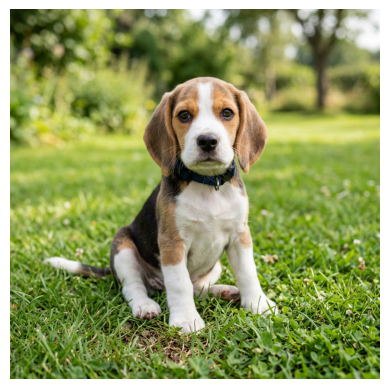

In [3]:
print("Dimensiones:", img.shape)
print("Píxel [10,10]:", img[10,10])

plt.imshow(img)
plt.axis("off")
plt.show()

## 4. Calcular las estadísticas globales

El mínimo, el máximo, la media y la desviación estándar se calculan sobre todos los valores de los tres canales. La desviación estándar mide la dispersión de esas intensidades respecto de su media.

In [4]:
print("Valor mínimo:", img.min())
print("Valor máximo:", img.max())
print("Media:", img.mean())
print("Desviación estándar:", img.std())

Valor mínimo: 0
Valor máximo: 255
Media: 119.40487066904704
Desviación estándar: 60.935034798738684


## 5. Visualizar el canal rojo

Se extrae `img[:, :, 0]` y se representa con el mapa de color `Reds`. La barra indica la intensidad entre 0 y 255; el mapa de color es una forma de visualizar un único canal.

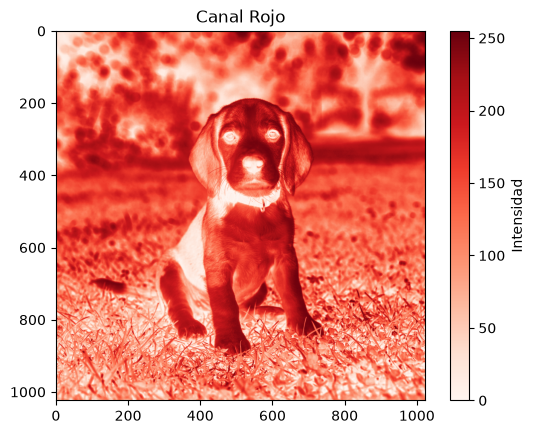

In [5]:
plt.imshow(img[:, :, 0], cmap="Reds", vmin=0, vmax=255)
plt.colorbar(label="Intensidad")
plt.title("Canal Rojo")
plt.show()

## 6. Visualizar el canal verde

Se extrae `img[:, :, 1]` y se utiliza la misma escala de intensidad para facilitar la comparación entre canales.

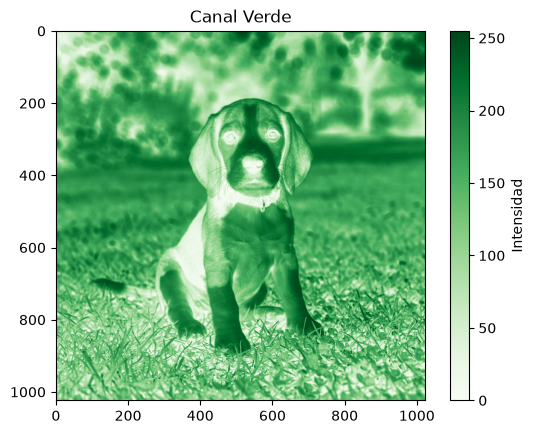

In [6]:
plt.imshow(img[:, :, 1], cmap="Greens", vmin=0, vmax=255)
plt.colorbar(label="Intensidad")
plt.title("Canal Verde")
plt.show()

## 7. Visualizar el canal azul

Se extrae `img[:, :, 2]` y se representa con el mapa de color `Blues`, también en el intervalo de 0 a 255.

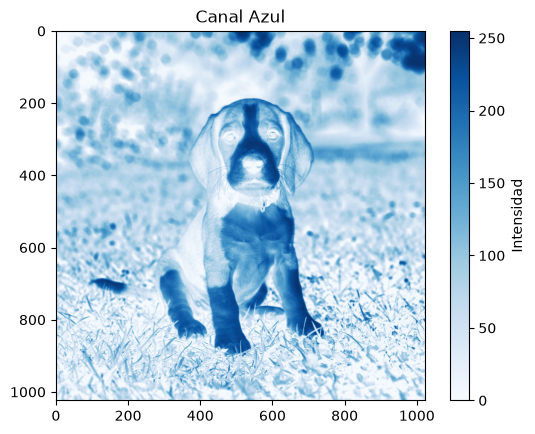

In [7]:
plt.imshow(img[:, :, 2], cmap="Blues", vmin=0, vmax=255)
plt.colorbar(label="Intensidad")
plt.title("Canal Azul")
plt.show()

## 8. Obtener la intensidad promedio por canal

Se calcula la media de cada matriz de canal por separado. El canal con mayor media es el de mayor intensidad promedio en esta imagen.

In [8]:
media_rojo = img[:, :, 0].mean()
media_verde = img[:, :, 1].mean()
media_azul = img[:, :, 2].mean()

print("Rojo:", media_rojo)
print("Verde:", media_verde)
print("Azul:", media_azul)

Rojo: 133.204363822937
Verde: 145.15760898590088
Azul: 79.85263919830322


## 9. Comparar los promedios con una gráfica de barras

Cada barra representa la media calculada en el apartado anterior y utiliza el color de su canal RGB correspondiente.

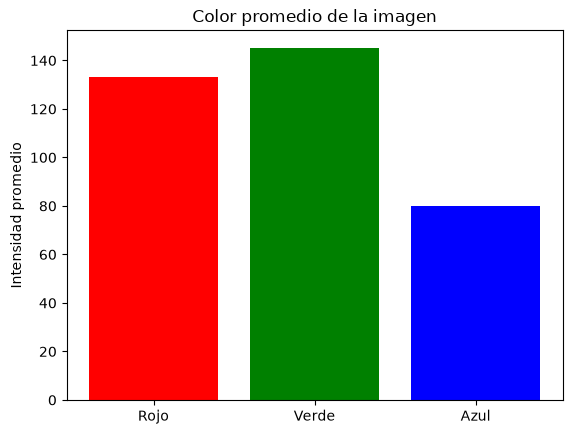

In [9]:
canales = ["Rojo", "Verde", "Azul"]
valores = [media_rojo, media_verde, media_azul]

plt.bar(canales, valores, color=["red", "green", "blue"])
plt.ylabel("Intensidad promedio")
plt.title("Color promedio de la imagen")
plt.show()

## 10. Convertir los píxeles en un DataFrame

`reshape(-1, 3)` conserva las ternas RGB y agrupa los píxeles en filas. El DataFrame tiene una fila por píxel y tres columnas. Se muestran su tamaño y sus primeras cinco filas.

In [10]:
datos = img.reshape(-1, 3)

df = pd.DataFrame(
    datos,
    columns=["Rojo", "Verde", "Azul"]
)

print("Dimensiones del DataFrame (filas, columnas):", df.shape)
print(df.head())

Dimensiones del DataFrame (filas, columnas): (1048576, 3)
   Rojo  Verde  Azul
0    29     46    10
1    27     44     8
2    30     45    12
3    28     43    10
4    29     43     8


## 11. Analizar la distribución del canal azul

`ravel()` reúne las intensidades del canal azul en un vector. El histograma agrupa esos valores en 50 intervalos: el eje horizontal indica intensidad y el vertical, cantidad de píxeles.

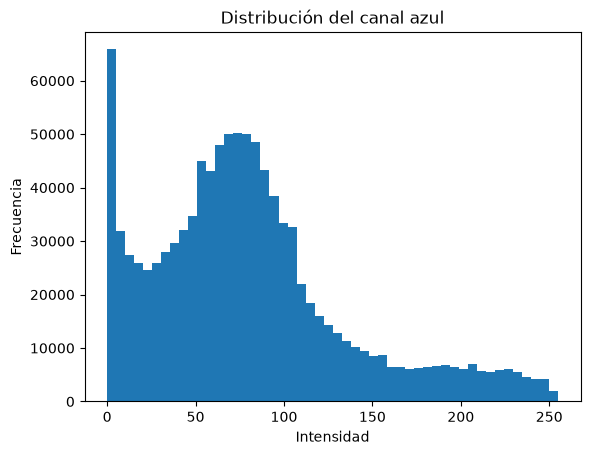

In [11]:
plt.hist(img[:,:,2].ravel(), bins=50)
plt.title("Distribución del canal azul")
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")
plt.show()

## Resultados e interpretación

Para el archivo `beagle.jpg` incluido en esta entrega:

- La imagen tiene **1024 × 1024 píxeles y 3 canales RGB**: su forma es `(1024, 1024, 3)` y sus valores son de tipo `uint8`.
- El píxel `[10, 10]` contiene **rojo = 22, verde = 35 y azul = 5**.
- Las intensidades globales van de **0 a 255**. La media es **119.404871** y la desviación estándar es **60.935035** (valores redondeados a seis decimales).
- Las medias por canal son **rojo = 133.204364**, **verde = 145.157609** y **azul = 79.852639**. El verde presenta la mayor intensidad promedio y el azul, la menor.
- El DataFrame contiene **1,048,576 filas y 3 columnas**: cada fila es un píxel y cada columna corresponde a un canal.
- El histograma permite observar cómo se distribuyen los valores azules. La altura de cada barra cuenta los píxeles cuyo valor cae en ese intervalo; no representa una coordenada de la fotografía.

Las seis figuras corresponden a la imagen original, los tres canales, la comparación de medias y el histograma del canal azul.